# 03 · Baselines & the backtest harness

Before building a clever model, we need a **fair way to measure** any model, and a **score to beat**.

## How a backtest works (rolling origin)
We replay history one gameweek at a time, exactly as if we were using the model live:

```
 GW 1 ─ GW 2 ─ … ─ GW g-1 │ GW g        → train on everything before g's deadline, predict g, compare with what happened
 GW 1 ─ GW 2 ─ … ─ GW g   │ GW g+1      → move forward one gameweek and repeat
```

- **Training data**: 2022-23 onwards (2021-22 is warm-up history for rolling features only).
- **Evaluated**: every gameweek of **2024-25, 2025-26 and 2026-27 so far**.
- Models are **retrained every 5 gameweeks** (cheap and realistic).
- Predictions are made **per fixture** and **summed per gameweek** (double gameweek = both matches), then compared
  with the player's actual gameweek total (your rule).

Code: [`fpl_engine/backtest.py`](../fpl_engine/backtest.py), [`fpl_engine/models/baselines.py`](../fpl_engine/models/baselines.py)

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db, backtest
from fpl_engine.features import load_base, build_features
from fpl_engine.models.baselines import all_baselines
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)
with db.connect() as conn:
    base = load_base(conn)
f = build_features(base)
preds = backtest.run(f, all_baselines())
gw = backtest.to_gameweeks(preds)
print(f"{gw.gw_key.nunique()} gameweeks evaluated, {len(gw):,} player-gameweeks per model")

87 gameweeks evaluated, 317,465 player-gameweeks per model


## The baselines

| Baseline | Prediction | Why include it |
|---|---|---|
| `zero` | 0 for everyone | the floor; shows why "all rows" metrics mislead |
| `last5_avg` | average points per squad fixture over the last 5 (bench = 0) | "recent form" in its simplest honest form |
| `season_avg` | average points per squad fixture this season | stable long-run average |
| `fpl_form` | official-style form: average points **per appearance** in the last 30 days | what the FPL app shows you |
| `simple_linear` | small ridge regression per position: recent minutes, starts, xGI/90, defensive/90, BPS/90, home, price | the "simple expected-points" baseline from the spec |

## Headline results: rotation-relevant players (your choice of population)

In [2]:
m = backtest.metrics(gw)
head = m.loc['rotation-relevant'].drop(index='zero', errors='ignore').sort_values('MAE')
head.round(3)

,rows,MAE,RMSE,bias,rank corr / GW,top20 picks: actual pts,top20 hindsight max
model,,,,,,,
simple_linear,26461,2.035,2.867,-0.025,0.433,4.770,10.952
season_avg,26461,2.129,3.026,-0.003,0.344,4.378,10.952
last5_avg,26461,2.234,3.102,0.196,0.319,4.195,10.952
fpl_form,26461,2.328,3.223,0.344,0.287,3.916,10.952


How to read each column:
- **MAE** (mean absolute error): on average, how many points off the prediction is. *Lower is better.*
- **RMSE**: like MAE but punishes big misses more (e.g. missing a 15-point haul). *Lower is better.*
- **bias**: average of (prediction − actual). Positive = over-predicts. Near 0 is good.
- **rank corr / GW**: within each gameweek, how well the model **orders** players (Spearman, 1 = perfect order).
  For picking a team or captain, ordering matters more than exact numbers.
- **top20 picks: actual pts**: each gameweek, take the model's 20 highest-predicted players; their average *actual*
  points. Compare with **hindsight max**, the best 20 that week. This is the most "FPL-like" number.

Note how `fpl_form` (the number the FPL app shows) does **worst**: it ignores whether the player actually plays,
and 30 days of points is mostly noise.

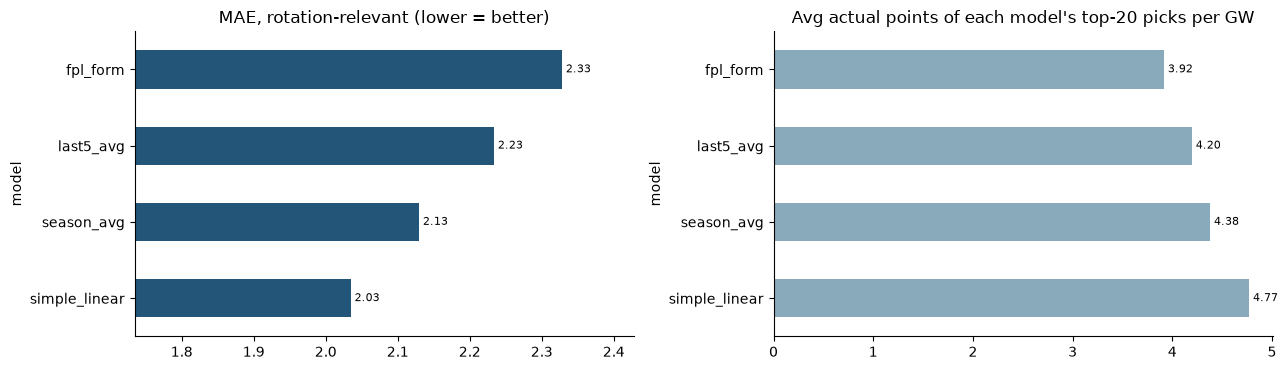

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
head['MAE'].plot.barh(ax=axes[0], color='#257'); axes[0].set_title('MAE, rotation-relevant (lower = better)')
axes[0].set_xlim(head.MAE.min() - .3, head.MAE.max() + .1)
head['top20 picks: actual pts'].plot.barh(ax=axes[1], color='#8ab'); axes[1].set_title('Avg actual points of each model\'s top-20 picks per GW')
for ax, col in zip(axes, ['MAE', 'top20 picks: actual pts']):
    for i, v in enumerate(head[col]): ax.text(v, i, f' {v:.2f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

## The other populations (for completeness)

In [4]:
m.loc[['played', 'all']].drop(columns=['top20 picks: actual pts', 'top20 hindsight max']).round(3)

rows    MAE   RMSE   bias  rank corr / GW
population model                                                    
played     fpl_form       26157  2.262  3.270 -0.216           0.267
           last5_avg      26157  2.213  3.192 -0.480           0.291
           season_avg     26157  2.120  3.116 -0.561           0.311
           simple_linear  26157  2.023  2.968 -0.567           0.357
           zero           26157  3.013  4.251 -2.988             NaN
all        fpl_form       63493  1.213  2.308  0.188           0.673
           last5_avg      63493  1.115  2.173  0.005           0.689
           season_avg     63493  1.124  2.138  0.019           0.671
           simple_linear  63493  1.099  2.007  0.032           0.684
           zero           63493  1.241  2.728 -1.231             NaN

On **all rows**, `zero` looks nearly competitive on MAE: most rows are bench players who score 0. That's the trap
from notebook 00, and why rotation-relevant is the headline.

## Where are the baselines weak? (spec §10 breakdowns)

In [5]:
gw['price_bracket'] = pd.cut(gw.price, [0, 5, 6.5, 8.5, 20], labels=['≤5.0', '5.1–6.5', '6.6–8.5', '8.6+'])
gw['minutes_bucket'] = pd.cut(gw.y_minutes, [-1, 0, 59, 90, 1000], labels=['0', '1–59', '60–90', 'DGW 90+'])
cols = ['simple_linear', 'season_avg', 'last5_avg', 'fpl_form']
for col, title in [('position', 'by position'), ('price_bracket', 'by price'), ('minutes_bucket', 'by actual minutes')]:
    print(f'MAE {title} (rotation-relevant)'); print(backtest.by_group(gw, col)[cols].round(2).to_string(), '\n')

MAE by position (rotation-relevant)
model     simple_linear  season_avg  last5_avg  fpl_form
position                                                
DEF                2.16        2.27       2.38      2.48
FWD                2.17        2.27       2.36      2.46
GKP                2.12        2.20       2.33      2.44
MID                1.90        1.99       2.09      2.18 

MAE by price (rotation-relevant)
model          simple_linear  season_avg  last5_avg  fpl_form
price_bracket                                                
≤5.0                    1.83        1.90       2.02      2.09
5.1–6.5                 2.07        2.18       2.27      2.39
6.6–8.5                 2.68        2.84       2.92      3.04
8.6+                    3.69        3.85       3.90      4.00 

MAE by actual minutes (rotation-relevant)
model           simple_linear  season_avg  last5_avg  fpl_form
minutes_bucket                                                
0                        1.65        1.78    

The biggest errors are for **expensive players** (bigger, more variable scores) and for players who ended up
**not playing** despite being regulars. The minutes model (notebook 04) attacks the second; the component models
(05–07) the first.

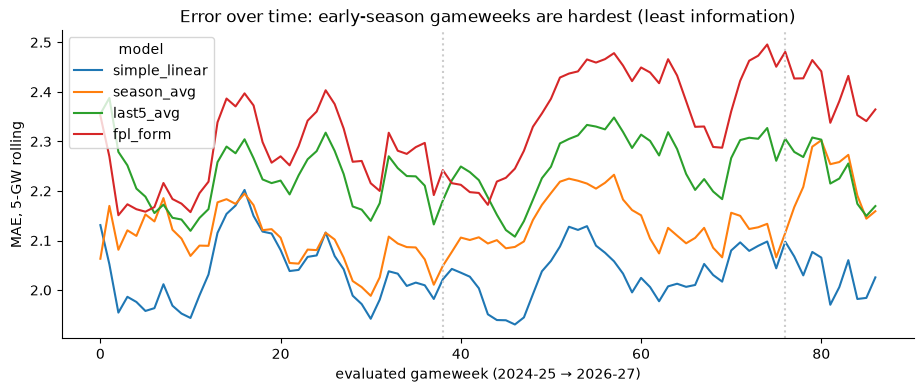

In [6]:
rr = gw[gw.rotation_relevant]
per_gw = rr.assign(ae=(rr.xpts - rr.y_points).abs()).groupby(['gw_key', 'model']).ae.mean().unstack()[cols]
ax = per_gw.rolling(5, min_periods=1).mean().reset_index(drop=True).plot(lw=1.5)
seasons = rr.drop_duplicates('gw_key').sort_values('gw_key').season.reset_index(drop=True)
for i in seasons[seasons != seasons.shift()].index[1:]: ax.axvline(i, color='#ccc', ls=':')
ax.set_xlabel('evaluated gameweek (2024-25 → 2026-27)'); ax.set_ylabel('MAE, 5-GW rolling')
ax.set_title('Error over time: early-season gameweeks are hardest (least information)'); plt.show()

## Probabilities: return (6+) and haul (10+)

The baselines only give a single number. Our real models will also give **P(6+ points)** and **P(10+ points)**,
judged with the **Brier score** (mean squared error of a probability; lower is better) and **calibration**
(when we say 30%, does it happen 30% of the time?). The simplest probability baseline is "everyone gets the base rate":

In [7]:
rrp = gw[gw.rotation_relevant & (gw.model == 'zero')]
for thr, name in [(6, 'return (6+)'), (10, 'haul (10+)')]:
    y = (rrp.y_points >= thr).astype(float); p = y.mean()
    print(f"{name:12s} base rate {p:.1%} · Brier of 'always predict base rate' = {((p - y) ** 2).mean():.4f}")

return (6+)  base rate 15.9% · Brier of 'always predict base rate' = 0.1335
haul (10+)   base rate 4.2% · Brier of 'always predict base rate' = 0.0399


In [8]:
import pathlib
out = pathlib.Path('../data/backtests'); out.mkdir(parents=True, exist_ok=True)
preds.to_parquet(out / 'baselines.parquet')
print('saved', out / 'baselines.parquet')

saved ../data/backtests/baselines.parquet


---
## 🎯 The bar to beat (rotation-relevant, per player-gameweek)
The best baseline is `simple_linear`. Our component model must beat it on **MAE**, **rank correlation** and
**top-20 picks**, and give calibrated return/haul probabilities that beat the base-rate Brier scores above.

## ✅ Decisions (made with you, 2026-11-23)
1. **Primary metric: top-20 picks' actual points** per gameweek (rotation-relevant). It's closest to how the model is
   used in FPL. **MAE and calibration are guard-rails**, so a model can't win by being badly off on exact numbers.
2. **Retrain every 5 gameweeks** while iterating; **every gameweek** for the final evaluation.
3. **Evaluate on 2024-25 onwards.**